# Chapitre 12 - Lab : dégrouper la base avec PostgreSQL et Redis

Les cours de ce chapitre défendent une idée : une organisation peut se construire comme
une **base de données dégroupée** (« unbundled »), où un système de référence publie le
journal ordonné de ses changements et où index, caches et compteurs sont des **vues
dérivées**, entretenues par des consommateurs idempotents et recalculables à volonté. Ce
lab met l'idée à l'épreuve sur de vrais systèmes : **PostgreSQL 17** joue le système de
référence, son **décodage logique** (plugin `test_decoding`) fournit le flux de
changements, et **Redis 7** héberge un index inversé et des compteurs dérivés. On y
provoque des pannes de consommateur, un bogue dans la fonction de dérivation, des
relances de requêtes et des courses sur une contrainte d'unicité.

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/dataflow/compose.yml -p ddia_dataflow up -d
# ... exécuter le notebook ...
docker compose -f docker/dataflow/compose.yml -p ddia_dataflow down -v
```

PostgreSQL écoute sur le port **11332** de l'hôte (utilisateur, mot de passe et base :
`ddia`), lancé avec `wal_level=logical` ; Redis écoute sur le port **11379**.

**Plan.**

1. Le journal de changements du système de référence.
2. Entretenir des vues dérivées dans Redis, et mesurer leur retard.
3. Panne du consommateur : relivraison et idempotence.
4. `CREATE INDEX CONCURRENTLY` : une vue dérivée construite par instantané et rattrapage.
5. Faire confiance, mais vérifier : audit de bout en bout d'une vue dérivée.
6. Corriger par retraitement : dériver une nouvelle vue à côté de l'ancienne.
7. Identifiants de requête de bout en bout.
8. Contraintes d'unicité sous concurrence.

In [1]:
import random
import threading
import time
import uuid
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg
import redis
from psycopg import errors

from ddia.dataflow_pg import InvertedIndexView, parse_change, rebuild_index, tokenize
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.max_colwidth", 90)
DSN = "host=localhost port=11332 user=ddia password=ddia dbname=ddia connect_timeout=5"
R = redis.Redis(host="localhost", port=11379, decode_responses=True)

with psycopg.connect(DSN, autocommit=True) as c:
    print(c.execute("SELECT version()").fetchone()[0].split(",")[0])
    print("wal_level =", c.execute("SHOW wal_level").fetchone()[0])
print("Redis", R.info("server")["redis_version"], "ping :", R.ping())


def sql(q, params=None):
    """Exécute une requête dans une connexion autocommit et renvoie les lignes."""
    with psycopg.connect(DSN, autocommit=True) as c:
        cur = c.execute(q, params)
        return cur.fetchall() if cur.description else None


# remise à zéro : le notebook peut être rejoué
for (slot,) in sql("SELECT slot_name FROM pg_replication_slots"):
    sql("SELECT pg_drop_replication_slot(%s)", (slot,))
sql("DROP TABLE IF EXISTS doc, mesures, comptes, requetes, journal_effets, "
    "utilisateurs, utilisateurs_u, demandes_noms CASCADE")
R.flushdb()

PostgreSQL 17.11 on x86_64-pc-linux-musl
wal_level = logical
Redis 7.4.11 ping : True


True

## 1. Le journal de changements du système de référence (section *Reasoning about dataflows*)

Le premier conseil du chapitre est de savoir **où une donnée est écrite d'abord** et
quelles représentations en dérivent. Ici, l'application n'écrit que dans PostgreSQL
(table `doc` : des articles avec titre, corps et auteur). Tout le reste, l'index de
recherche et les compteurs par auteur dans Redis, est **dérivé** du flux de changements
de cette table, dans l'ordre où PostgreSQL les a validés. L'application n'écrit jamais
directement dans Redis : il n'y a donc pas de double écriture et pas de course entre
deux systèmes qui décideraient chacun d'un ordre (chapitre 11).

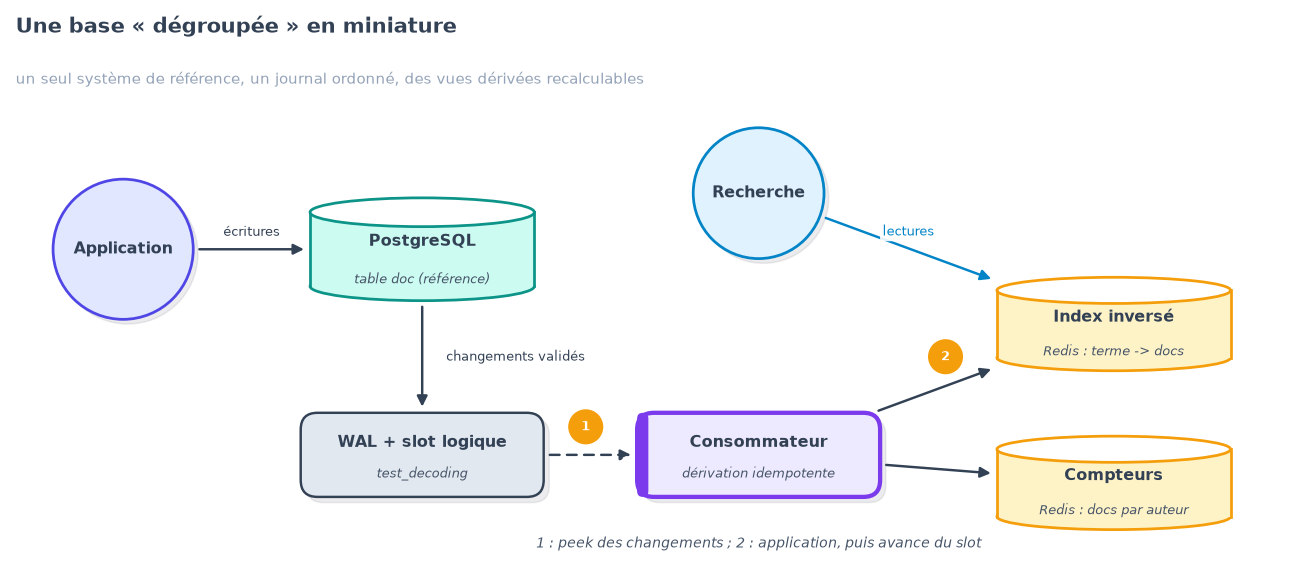

In [2]:
d = Diagram(13.6, 5.0, title="Une base « dégroupée » en miniature",
            subtitle="un seul système de référence, un journal ordonné, des vues dérivées recalculables")
d.box("app", 1.2, 3.4, "Application", kind="user", w=1.5, color=INDIGO)
d.box("pg", 4.4, 3.4, "PostgreSQL", sub="table doc (référence)", kind="db", color=TEAL, w=2.4, h=1.1)
d.box("wal", 4.4, 1.2, "WAL + slot logique", sub="test_decoding", color=SLATE, w=2.6)
d.box("cons", 8.0, 1.2, "Consommateur", sub="dérivation idempotente", color=VIOLET, w=2.6, kind="model")
d.box("idx", 11.8, 2.6, "Index inversé", sub="Redis : terme -> docs", kind="db", color=AMBER, w=2.5, h=1.0)
d.box("cnt", 11.8, 0.9, "Compteurs", sub="Redis : docs par auteur", kind="db", color=AMBER, w=2.5, h=1.0)
d.box("q", 8.0, 4.0, "Recherche", kind="user", w=1.4, color=SKY)
d.arrow("app", "pg", "écritures")
d.arrow("pg", "wal", "changements validés", label_offset=(1.0, 0))
d.arrow("wal", "cons", style="dashed")
d.arrow("cons", "idx")
d.arrow("cons", "cnt")
d.arrow("q", "idx", "lectures", color=SKY)
d.badge(6.15, 1.5, "1"); d.badge(10.0, 2.25, "2")
d.note(8.0, 0.25, "1 : peek des changements ; 2 : application, puis avance du slot")
d.show()

Un **slot de réplication logique** est un curseur durable sur le journal d'écriture
(WAL) : PostgreSQL conserve tout le journal qui n'a pas encore été confirmé par ce
consommateur. `pg_logical_slot_peek_changes` lit les changements sans faire avancer le
curseur ; `pg_replication_slot_advance` le fait avancer une fois les changements
appliqués. C'est exactement l'offset d'un consommateur de journal du chapitre
11, géré par la base elle-même.

In [3]:
sql("""CREATE TABLE doc (id integer PRIMARY KEY, titre text NOT NULL, corps text NOT NULL,
                         auteur text)""")
sql("SELECT pg_create_logical_replication_slot('vues', 'test_decoding')")


def peek(slot, max_rows=None):
    return sql("SELECT lsn::text, xid::text, data FROM pg_logical_slot_peek_changes(%s, NULL, %s)",
               (slot, max_rows))


def advance(slot, lsn):
    sql("SELECT pg_replication_slot_advance(%s, %s::pg_lsn)", (slot, lsn))


sql("INSERT INTO doc VALUES (1, 'Journaux et flux', 'Le journal ordonne les événements', 'ana')")
sql("UPDATE doc SET titre = 'Journaux, flux et vues' WHERE id = 1")
with psycopg.connect(DSN) as c:      # une transaction de deux changements
    c.execute("INSERT INTO doc VALUES (2, 'L''index dérivé', 'Une vue sur les données', 'bob')")
    c.execute("DELETE FROM doc WHERE id = 1")
brut = pd.DataFrame(peek("vues"), columns=["lsn", "xid", "data"])
brut

,lsn,xid,data
0,0/1DE7A850,15888,BEGIN 15888
1,0/1DE7A850,15888,table public.doc: INSERT: id[integer]:1 titre[text]:'Journaux et flux' corps[text]:'Le...
2,0/1DE7A998,15888,COMMIT 15888
3,0/1DE7A998,15889,BEGIN 15889
4,0/1DE7A998,15889,"table public.doc: UPDATE: id[integer]:1 titre[text]:'Journaux, flux et vues' corps[tex..."
5,0/1DE7AA50,15889,COMMIT 15889
6,0/1DE7AA50,15890,BEGIN 15890
7,0/1DE7AA50,15890,table public.doc: INSERT: id[integer]:2 titre[text]:'L''index dérivé' corps[text]:'Une...
8,0/1DE7AB00,15890,table public.doc: DELETE: id[integer]:1
9,0/1DE7AB70,15890,COMMIT 15890


Chaque transaction validée apparaît entre un `BEGIN` et un `COMMIT`, dans l'ordre de
validation, avec l'image complète de la nouvelle ligne pour `INSERT` et `UPDATE` (et la
clé seule pour `DELETE`, l'identité de réplique par défaut). Le parseur
`parse_change` du module `ddia/dataflow_pg.py` transforme ces lignes en changements
structurés :

In [4]:
pd.DataFrame([dict(op=c["op"], **c["row"]) for c in map(parse_change, brut["data"]) if c])

,op,id,titre,corps,auteur
0,INSERT,1,Journaux et flux,Le journal ordonne les événements,ana
1,UPDATE,1,"Journaux, flux et vues",Le journal ordonne les événements,ana
2,INSERT,2,L'index dérivé,Une vue sur les données,bob
3,DELETE,1,NaN,NaN,NaN


> **À retenir.** Le système de référence décide seul de l'ordre des écritures ; son
> journal de changements, lu à travers un slot logique (un offset durable), est l'unique
> entrée des systèmes dérivés.

## 2. Entretenir des vues dérivées dans Redis, et mesurer leur retard (section *The meta-database of everything*)

Le consommateur applique chaque changement à deux vues Redis : un **index inversé**
(`t:<terme>` = ensemble des documents contenant le terme) et un **compteur de documents
par auteur** (un hash). Pour rester **idempotent**, il mémorise pour chaque document ses
termes (`doc:<id>`) et son auteur (`auth:<id>`) : appliquer un changement consiste à
retirer l'ancienne contribution du document puis à ajouter la nouvelle, le tout dans une
transaction Redis (`MULTI`). Rejouer un changement déjà appliqué ne modifie donc rien.
Pour comparaison, il entretient aussi un compteur **naïf** du nombre total de documents
(`INCR` sur insertion, `DECR` sur suppression), qui n'est pas idempotent.

C'est ce que fait une base quand elle maintient un index secondaire, mais l'index est
ici un autre logiciel, sur une autre machine potentiellement, entretenu par du code
applicatif : la base de toute l'organisation devient une « méta-base ».

In [5]:
def apply_redis(ch, v="v1", tok=tokenize):
    """Applique un changement à la vue `v` (idempotent), plus le compteur naïf."""
    p = f"idx:{v}:"
    i = ch["row"]["id"]
    old_terms, old_auth = R.smembers(p + f"doc:{i}"), R.get(p + f"auth:{i}")
    pipe = R.pipeline(transaction=True)
    for t in old_terms:
        pipe.srem(p + "t:" + t, i)
    pipe.delete(p + f"doc:{i}", p + f"auth:{i}")
    if old_auth:
        pipe.hincrby(p + "auteurs", old_auth, -1)
    if ch["op"] != "DELETE":
        row = ch["row"]
        terms = tok(row["titre"]) | tok(row["corps"])
        for t in terms:
            pipe.sadd(p + "t:" + t, i)
        if terms:
            pipe.sadd(p + f"doc:{i}", *terms)
        if row["auteur"]:
            pipe.set(p + f"auth:{i}", row["auteur"])
            pipe.hincrby(p + "auteurs", row["auteur"], 1)
    pipe.incrby(p + "naif_total", {"INSERT": 1, "DELETE": -1}.get(ch["op"], 0))
    pipe.execute()


class Crash(Exception):
    """Panne simulée du consommateur."""


def consume(slot, v="v1", max_rows=None, crash_after=None, tok=tokenize):
    """Lit les changements du slot, les applique, puis avance le slot jusqu'au dernier COMMIT.
    crash_after=k : panne après k changements appliqués, avant l'avance du slot."""
    rows, applied, last_commit = peek(slot, max_rows), 0, None
    for lsn, _, data in rows:
        if data.startswith("COMMIT"):
            last_commit = lsn
            continue
        ch = parse_change(data)
        if ch is None or ch["table"] != "doc":
            continue
        if crash_after is not None and applied == crash_after:
            raise Crash(f"panne après {applied} changements")
        apply_redis(ch, v, tok)
        applied += 1
    if last_commit:
        advance(slot, last_commit)
    return applied


print("changements appliqués :", consume("vues"))
print("doc 2 :", R.smembers("idx:v1:doc:2"), "| auteurs :", R.hgetall("idx:v1:auteurs"))

changements appliqués : 4
doc 2 : {'derive', 'donnee', 'index', 'sur', 'vue'} | auteurs : {'ana': '0', 'bob': '1'}


Générons maintenant une charge synthétique d'articles (vocabulaire du livre, auteurs
tirés selon une loi de Zipf) et observons le **retard** de la vue. Le temps est découpé
en 60 pas ; à chaque pas, l'application valide quelques transactions (avec un pic entre
les pas 20 et 32), puis le consommateur lit **au plus 60 lignes** du flux (il ne coupe
jamais une transaction). On mesure le nombre de changements en attente et le volume de
WAL que PostgreSQL doit conserver pour ce slot.

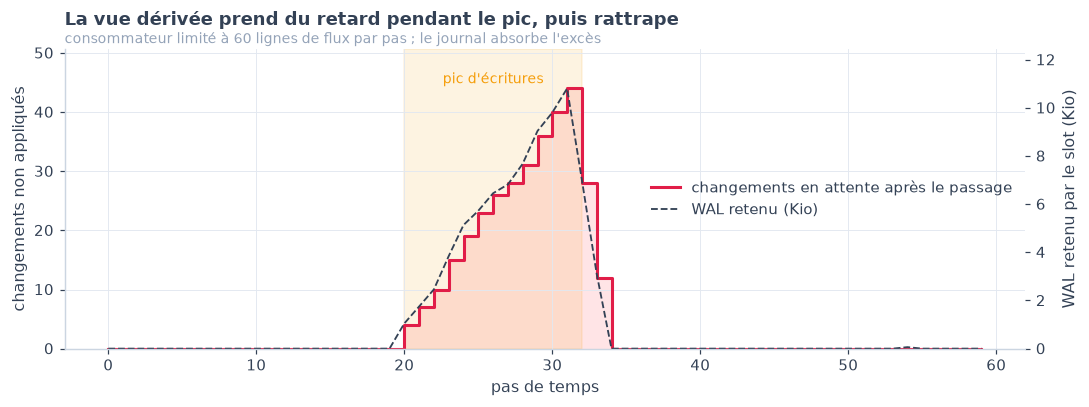

documents dans PostgreSQL : 301 | retard final : 0


In [6]:
MOTS = ["journal", "flux", "données", "index", "réplique", "cache", "requête", "événement",
        "horloge", "consensus", "transaction", "schéma", "vue", "débit", "latence", "panne",
        "courtier", "capture", "clé", "dérivée", "unicité", "audit", "idempotence", "lot"]
AUTEURS = ["ana", "bob", "chloé", "driss", "elsa", "farid"]
POIDS = [1 / (k + 1) for k in range(len(AUTEURS))]
gen = random.Random(13)
prochain_id = [100]


def phrase(n):
    return " ".join(gen.choice(MOTS) for _ in range(n)).capitalize()


def ecrire(n_tx, conn):
    """n_tx transactions : surtout des insertions, quelques mises à jour et suppressions."""
    n = 0
    for _ in range(n_tx):
        u = gen.random()
        if u < 0.7 or prochain_id[0] < 120:
            prochain_id[0] += 1
            conn.execute("INSERT INTO doc VALUES (%s, %s, %s, %s)",
                         (prochain_id[0], phrase(3), phrase(8), gen.choices(AUTEURS, POIDS)[0]))
        elif u < 0.9:
            conn.execute("UPDATE doc SET corps = %s, auteur = %s WHERE id = %s",
                         (phrase(8), gen.choices(AUTEURS, POIDS)[0], gen.randint(101, prochain_id[0])))
        else:
            conn.execute("DELETE FROM doc WHERE id = %s", (gen.randint(101, prochain_id[0]),))
        n += 1
    return n


def en_attente(slot):
    """Nombre de changements de lignes encore dans le slot (non confirmés)."""
    return sql("""SELECT count(*) FROM pg_logical_slot_peek_changes(%s, NULL, NULL)
                  WHERE data LIKE 'table %%'""", (slot,))[0][0]


def wal_retenu(slot):
    return sql("""SELECT pg_wal_lsn_diff(pg_current_wal_lsn(), confirmed_flush_lsn)
                  FROM pg_replication_slots WHERE slot_name = %s""", (slot,))[0][0]


mesures_retard = []
with psycopg.connect(DSN, autocommit=True) as w:
    for pas in range(60):
        ecrire(25 if 20 <= pas < 32 else 4, w)
        consume("vues", max_rows=60)
        mesures_retard.append((pas, en_attente("vues"), float(wal_retenu("vues"))))
ret = pd.DataFrame(mesures_retard, columns=["pas", "en attente", "WAL retenu (o)"])

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(ret["pas"], ret["en attente"], color=LIGHT[ROSE], step="post")
ax.step(ret["pas"], ret["en attente"], where="post", color=ROSE, label="changements en attente après le passage")
ax.axvspan(20, 32, color=AMBER, alpha=0.12)
ax.text(26, ret["en attente"].max() * 1.02, "pic d'écritures", ha="center", color=AMBER, fontsize=9)
ax2 = ax.twinx()
ax2.plot(ret["pas"], ret["WAL retenu (o)"] / 1024, color=SLATE, lw=1.2, ls="--", label="WAL retenu (Kio)")
ax2.set_ylabel("WAL retenu par le slot (Kio)"); ax2.grid(False)
ax.set_xlabel("pas de temps"); ax.set_ylabel("changements non appliqués")
ax.set_ylim(0, ret["en attente"].max() * 1.15)
ax.set_title("La vue dérivée prend du retard pendant le pic, puis rattrape")
subtitle(ax, "consommateur limité à 60 lignes de flux par pas ; le journal absorbe l'excès")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax2.set_ylim(0, ret["WAL retenu (o)"].max() / 1024 * 1.15)
ax.legend(h1 + h2, l1 + l2, loc="center right")
plt.tight_layout(); plt.show()
print("documents dans PostgreSQL :", sql("SELECT count(*) FROM doc")[0][0],
      "| retard final :", ret["en attente"].iloc[-1])

Pendant le pic, l'application écrit plus vite que le consommateur ne lit : l'écart
grossit, et PostgreSQL retient le WAL correspondant. Les écritures ne sont **jamais
ralenties** par la vue lente : le journal sert de tampon, et la faute (ici, une simple
lenteur) reste confinée à la vue. Une fois le pic passé, la marge de capacité résorbe le
retard. Le prix est la **fraîcheur** : pendant quelques pas, une recherche dans Redis ne
trouve pas les articles qui viennent d'être publiés, alors que PostgreSQL les contient
déjà. Vérifions la fraîcheur à un instant donné :

In [7]:
with psycopg.connect(DSN, autocommit=True) as w:
    prochain_id[0] += 1
    nid = prochain_id[0]
    w.execute("INSERT INTO doc VALUES (%s, 'Watermark tardif', 'un article tout frais', 'ana')", (nid,))
print("dans PostgreSQL :", sql("SELECT count(*) FROM doc WHERE id = %s", (nid,))[0][0] == 1,
      "| trouvé dans l'index Redis :", nid in {int(x) for x in R.smembers("idx:v1:t:watermark")})
consume("vues")
print("après passage du consommateur :", nid in {int(x) for x in R.smembers("idx:v1:t:watermark")})

dans PostgreSQL : True | trouvé dans l'index Redis : False
après passage du consommateur : True


> **À retenir.** Un consommateur de journal entretient une vue dérivée comme une base
> entretient un index, mais de façon asynchrone : une vue lente prend du retard sans
> ralentir les écritures, et le journal retenu par le slot mesure ce retard.